In [19]:
import subprocess
from pathlib import Path

import networkx as nx
import matplotlib.pyplot as plt

In [ ]:
# Helpers: run the C++ driver, read back what it wrote, and report it in the
# format of "sample outputs.pdf". All paths are relative to the project root,
# which is where this notebook lives and runs.
#
# The driver is not built here: run `make` in the project root first.

DRIVER = "./wait_for_graph"


def run(cmd, **kwargs):
    """Runs a command, raising with the command's own error output if it fails."""
    result = subprocess.run(cmd, capture_output=True, text=True, **kwargs)
    if result.returncode != 0:
        raise RuntimeError(f"{' '.join(cmd)} failed:\n{result.stderr}")
    return result


def run_driver(i, input_path):
    """Runs the driver on the transactions in input_path as run number i, then
    parses the two files it writes. Returns the round-robin schedule (one line
    of text) and the wait-for graph (a networkx DiGraph)."""
    if not Path(DRIVER).exists():
        raise FileNotFoundError(f"{DRIVER} not found: build it first by running `make` in the project root")
    with open(input_path) as transactions:
        run([DRIVER, str(i)], stdin=transactions)
    schedule = Path(f"output_schedules/out_{i}.txt").read_text().strip()
    graph = nx.read_graphml(f"graphs/wait_for_graph_{i}.graphml")
    # The driver stops reading at the first line that does not start with 'T',
    # so a file in the wrong format gives a graph with no transactions at all
    if graph.number_of_nodes() == 0:
        raise ValueError(f"No transactions found in {input_path}: it needs one "
                         "transaction per line, starting on the first line, "
                         "like 'T1: R(a); W(b,1); C'")
    return schedule, graph


def trans_num(name):
    """'T12' -> 12, so that transactions sort as T1, T2, ..., T10."""
    return int(name[1:])


def find_cycles(g):
    """Every cycle in the graph as a list of transactions, each starting from
    its lowest-numbered one, e.g. [['T1', 'T2'], ['T2', 'T3']]."""
    cycles = []
    for cycle in nx.simple_cycles(g):
        start = cycle.index(min(cycle, key=trans_num))
        cycles.append(cycle[start:] + cycle[:start])
    return sorted(cycles, key=lambda cycle: [trans_num(t) for t in cycle])


def describe_cycle(cycle):
    """['T1', 'T2'] -> 'T1 to T2 (or T2 to T1)': the cycle read from its first
    transaction, then from each of the others."""
    readings = [" to ".join(cycle[k:] + cycle[:k]) for k in range(len(cycle))]
    return f"{readings[0]} (or {' or '.join(readings[1:])})"


def draw_graph(g):
    """Draws the wait-for graph with every edge labelled by its transaction_op
    attribute, the operation that had to wait."""
    rad = 0.3   # Curvature of the edges, so that T1->T2 and T2->T1 do not overlap
    plt.figure(figsize=(6, 6))
    # Transactions go round a circle of radius 1, in order
    pos = nx.circular_layout(sorted(g.nodes, key=trans_num))
    nx.draw(g, pos, with_labels=True, node_size=1500, node_color='white',
            edgecolors='black', connectionstyle=f'arc3, rad={rad}')
    # A fixed, square view of the circle: every graph is drawn at the same
    # scale, and the label positions below land on the curves
    plt.xlim(-1.5, 1.5)
    plt.ylim(-1.5, 1.5)
    plt.gca().set_aspect('equal')

    # Put each label at the middle of its own edge's curve, so the two
    # directions between a pair of transactions stay apart
    for u, v, op in g.edges(data='transaction_op'):
        (x1, y1), (x2, y2) = pos[u], pos[v]
        plt.text((x1 + x2)/2 + rad*(y2 - y1)/2, (y1 + y2)/2 - rad*(x2 - x1)/2, op,
                 ha='center', va='center', fontsize=9,
                 bbox=dict(boxstyle='round', fc='white', ec='none'))
    plt.show()


def report(i, input_path, title=None):
    """Runs the driver on input_path as run number i and prints the input and
    the three outputs, under the heading `title` ("Test Case i" if not given)."""
    schedule, g = run_driver(i, input_path)
    print(title or f"Test Case {i}")
    print("Input Example:")
    print(Path(input_path).read_text().strip())
    print("Output 1: The ordering of operations in the schedule (round-robin):")
    print(schedule)
    print("Output 2: The wait-for graph will be:")
    draw_graph(g)
    cycles = find_cycles(g)
    if not cycles:
        print("Output 3: No Cycle.")
    for k, cycle in enumerate(cycles, start=1):
        # Only the first cycle carries the "Output 3:" heading
        heading = "Output 3: " if k == 1 else " " * len("Output 3: ")
        print(f"{heading}Cycle {k}: {describe_cycle(cycle)}")
    print()

# Given Sample Input Checks

Test Case 1
Input Example:
T1: R(a); W(b,1); C
T2: R(b); R(c); W(a,2); C
T3: R(a); W(c,3); C
Output 1: The ordering of operations in the schedule (round-robin):
T1:R(a); T2:R(b); T3:R(a); T1:W(b,1); T2:R(c); T3:W(c,3); T1:C; T2:W(a,2); T3:C; T2:C
Output 2: The wait-for graph will be:


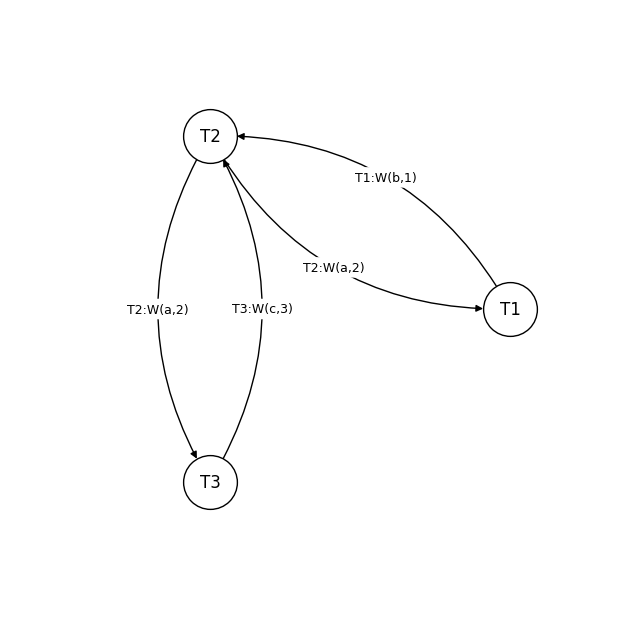

Output 3: Cycle 1: T1 to T2 (or T2 to T1)
          Cycle 2: T2 to T3 (or T3 to T2)

Test Case 2
Input Example:
T1:R(g); W(h,2); W(e,8); C
T2:R(e); W(c,4); R(h); C
T3:R(j); R(g); W(b,9); C
Output 1: The ordering of operations in the schedule (round-robin):
T1:R(g); T2:R(e); T3:R(j); T1:W(h,2); T2:W(c,4); T3:R(g); T1:W(e,8); T2:R(h); T3:W(b,9); T1:C; T2:C; T3:C
Output 2: The wait-for graph will be:


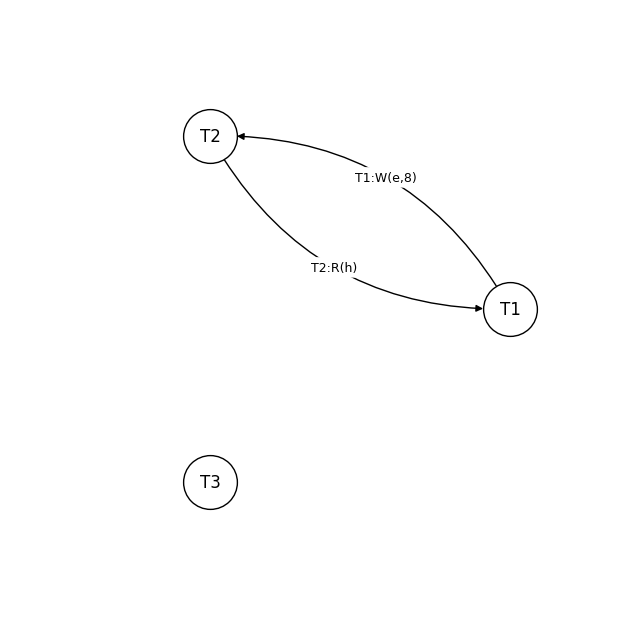

Output 3: Cycle 1: T1 to T2 (or T2 to T1)

Test Case 3
Input Example:
T1:W(b,5);R(c);W(c,3);R(b);C
T2:R(b);W(b,2);C
Output 1: The ordering of operations in the schedule (round-robin):
T1:W(b,5); T2:R(b); T1:R(c); T2:W(b,2); T1:W(c,3); T2:C; T1:R(b); T1:C
Output 2: The wait-for graph will be:


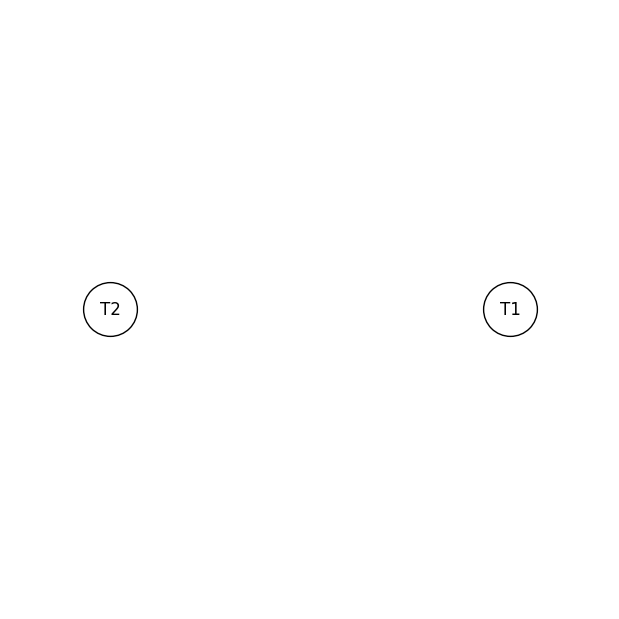

Output 3: No Cycle.



In [21]:
# Run the driver on the three test cases of "sample outputs.pdf"
for i in [1, 2, 3]:
    report(i, f"tests/test{i}.txt")

# Custom Input Check

In [ ]:
# Required: the path to your own input txt file, with one transaction per
# line in the same format as the samples, e.g.
#     T1: R(a); W(b,1); C
#     T2: R(b); W(a,2); C
custom_input_path = ""

if not custom_input_path:
    raise ValueError("Set custom_input_path above to the path of your input txt file")
if not Path(custom_input_path).is_file():
    raise FileNotFoundError(f"No such input file: {custom_input_path}")

# Run number 0 keeps the custom outputs (output_schedules/out_0.txt and
# graphs/wait_for_graph_0.graphml) apart from those of the sample tests
report(0, custom_input_path, title="Custom Input")